In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
df = sns.load_dataset("titanic")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [ ]:
df.shape


(891, 15)

In [ ]:
df.columns

Index(['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare',
       'embarked', 'class', 'who', 'adult_male', 'deck', 'embark_town',
       'alive', 'alone'],
      dtype='object')

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    object  
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    object  
 8   class        891 non-null    category
 9   who          891 non-null    object  
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    object  
 13  alive        891 non-null    object  
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), object(5)
memory usage: 80.7+ KB


In [ ]:
df.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [ ]:
df.isnull().sum()

,0
survived,0
pclass,0
sex,0
age,177
sibsp,0
parch,0
fare,0
embarked,2
class,0
who,0


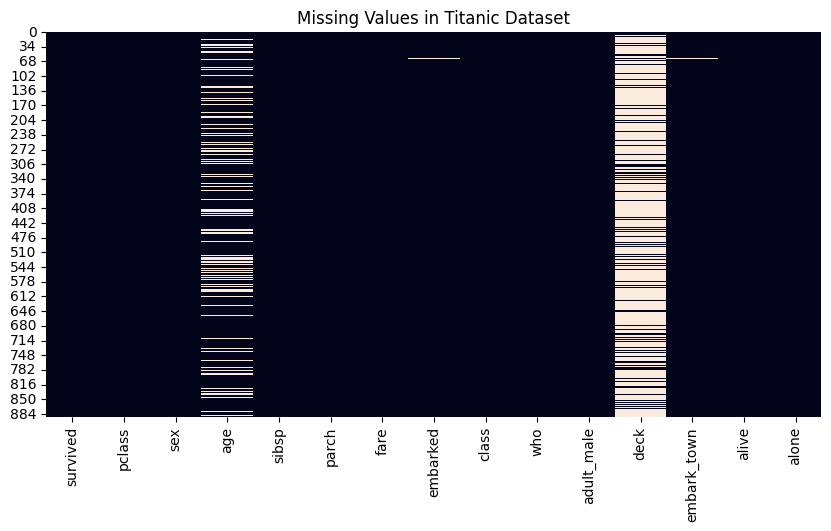

In [ ]:
plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False)

plt.title("Missing Values in Titanic Dataset")
plt.show()

In [ ]:
print(df["survived"].value_counts())

survived
0    549
1    342
Name: count, dtype: int64


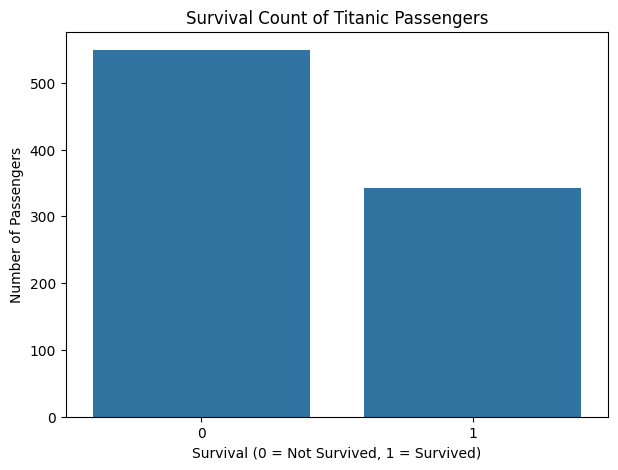

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="survived")

plt.title("Survival Count of Titanic Passengers")
plt.xlabel("Survival (0 = Not Survived, 1 = Survived)")
plt.ylabel("Number of Passengers")

plt.show()

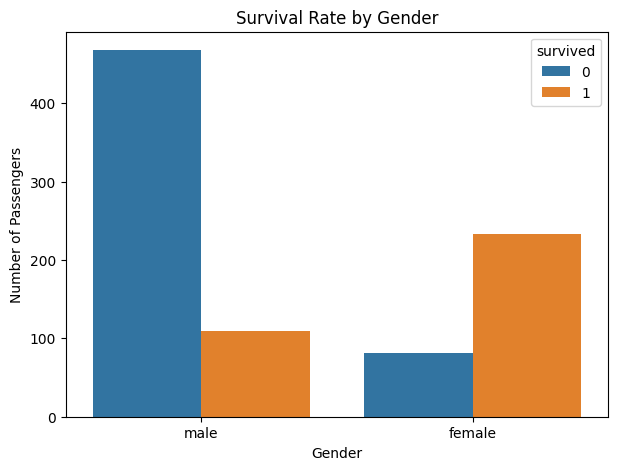

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="sex", hue="survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Passengers")

plt.show()

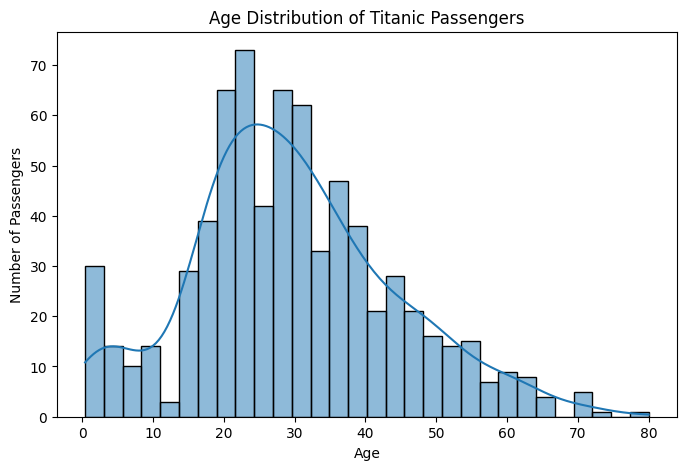

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(df["age"].dropna(), bins=30, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

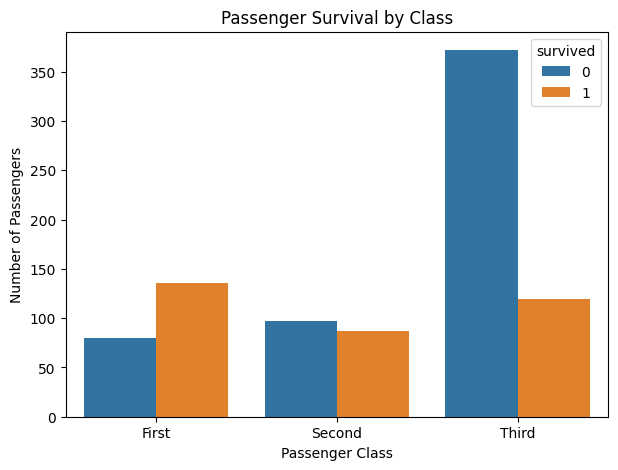

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="class", hue="survived")

plt.title("Passenger Survival by Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")

plt.show()

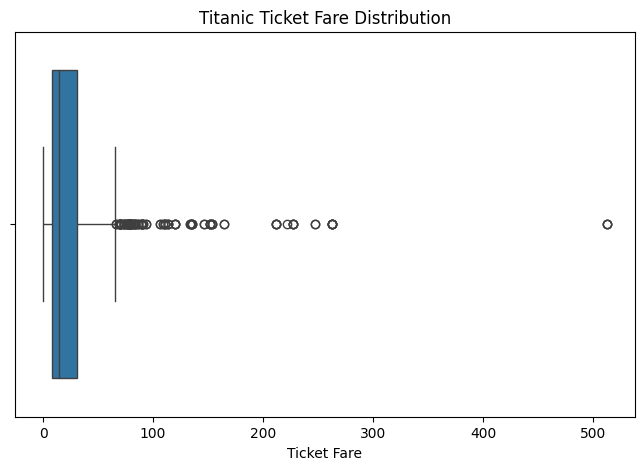

In [ ]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["fare"])

plt.title("Titanic Ticket Fare Distribution")
plt.xlabel("Ticket Fare")

plt.show()

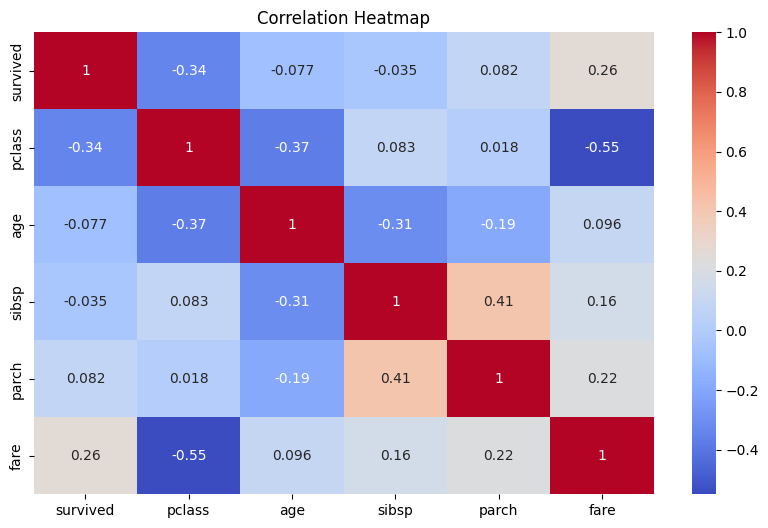

In [ ]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
from scipy.stats import chi2_contingency

table = pd.crosstab(df["sex"], df["survived"])

chi2, p, dof, expected = chi2_contingency(table)

print("Chi-square value:", chi2)
print("P-value:", p)

if p < 0.05:
    print("Reject Null Hypothesis")
    print("Gender and survival are associated.")
else:
    print("Fail to Reject Null Hypothesis")
    print("No significant association found.")

Chi-square value: 260.71702016732104
P-value: 1.1973570627755645e-58
Reject Null Hypothesis
Gender and survival are associated.


In [ ]:
cleaned_df = df.copy()

cleaned_df["age"] = cleaned_df["age"].fillna(
    cleaned_df["age"].median()
)

cleaned_df["embarked"] = cleaned_df["embarked"].fillna(
    cleaned_df["embarked"].mode()[0]
)

print("Missing values after cleaning:")
print(cleaned_df.isnull().sum())

Missing values after cleaning:
survived         0
pclass           0
sex              0
age              0
sibsp            0
parch            0
fare             0
embarked         0
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


In [ ]:
print("TOTAL PASSENGERS:", len(df))

print("SURVIVED:", df["survived"].sum())

print("NOT SURVIVED:", (df["survived"] == 0).sum())

print("AVERAGE AGE:", round(df["age"].mean(), 2))

print("AVERAGE FARE:", round(df["fare"].mean(), 2))

TOTAL PASSENGERS: 891
SURVIVED: 342
NOT SURVIVED: 549
AVERAGE AGE: 29.7
AVERAGE FARE: 32.2


In [ ]:
cleaned_df.to_csv("titanic_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
